# Week 15 — Forward Diffusion on MNIST

**Mode: tutorial · Day 4 · three implementation exercises · CPU**

**Companion:** [the forward-process note and your Day 3 derivation](../notes/w15_forward_process_discrete.md#day-3--deriving-the-forward-distributions).

**Workflow:** The unsolved and _solved files start as identical copies.
Work in **w15_forward_diffusion_mnist_solved.ipynb** and keep the unsolved file
as the exercise baseline. The working copy still contains the exercises;
the filename does not mean they have already been solved.

## Learning Goals

Turn your derivation into a small numerical experiment:

1. Construct cumulative coefficients with an explicit clean-input boundary.
2. Implement a single Gaussian step and direct noising from a clean image.
3. Interpret coefficient curves and image grids using the same clean digits.

You need NumPy, plotting basics, and the conditional mean/covariance result
from Days 1–3. Data loading, plotting, and deterministic checks are provided.
Fill only the **three marked exercise cells**. An unfinished exercise raises
a named error when its check cell first calls it.

**Time budget:** about 60 minutes, including discussion: roughly 10 for setup,
25 for the three exercises, 15 for plots, and 10 for interpretation.
If a step takes longer, bring the attempt for review.

## Outline

1. Setup: cached MNIST and normalization.
2. Step 1: a linear schedule and one-step corruption.
3. Step 2: direct sampling, boundary checks, and two image grids.
4. Exercise: explain three observations.
5. Wrap-up: the Day 4 stopping point and Day 5 handoff.

Read or reread the schedule and forward-sampling code in
[Annotated Diffusion](https://huggingface.co/blog/annotated-diffusion#defining-the-forward-diffusion-process)
as a reference when needed. Our implementations are small NumPy versions of
the equations you derived; this notebook uses the existing project dependencies.

---
## Setup

Run from the repository root or the notebooks directory using the project's
Python environment. All generated files stay under the ignored scratch directory.
No GPU is needed.

In [1]:
from pathlib import Path
import gzip
import hashlib
import os
import struct
import urllib.request

import numpy as np

ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "pyproject.toml").exists() and (p / "notebooks").is_dir()
)
CACHE = ROOT / "scratch" / "w15_forward_diffusion"
CACHE.mkdir(parents=True, exist_ok=True)
FIGURE_DIR = CACHE / "figures"
FIGURE_DIR.mkdir(exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(CACHE / "matplotlib"))
import matplotlib.pyplot as plt

SEED = 15
rng = np.random.default_rng(SEED)
config = {
    "seed": SEED,
    "T": 1000,
    "beta_start": 1e-4,
    "beta_end": 0.02,
    "digits": (0, 1, 4, 7),
    "display_times": (0, 1, 50, 100, 250, 500, 1000),
    "normalization": "uint8 / 127.5 - 1",
}
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
})
assert config["T"] >= max(config["display_times"])
assert 0 < config["beta_start"] <= config["beta_end"] < 1
print(f"NumPy on CPU | seed={SEED} | T={config['T']} | outputs: {FIGURE_DIR}")

NumPy on CPU | seed=15 | T=1000 | outputs: /Users/juanpineros/juancopi81/diffusion-research-curriculum/scratch/w15_forward_diffusion/figures


### Provided infrastructure: MNIST and a fixed set of clean inputs

This reuses the checksum-verified IDX/gzip loading approach from the
[Week 11 VAE notebook](w11_minimal_vae_mnist.ipynb). It first looks for the
two existing test-set files under scratch/w11_vae/mnist; a missing file is
downloaded from the same [MNIST mirror](https://ossci-datasets.s3.amazonaws.com/mnist/)
into this week's ignored cache. The cached files are checked before decoding.

The arrays use **(batch, channel, height, width)** order. We map byte pixels
to $[-1,1]$, so the clean image scale is explicit relative to unit Gaussian
noise. This centers the available pixel range, without asserting a zero
dataset mean or unit dataset variance.

In [2]:
MNIST_URL = "https://ossci-datasets.s3.amazonaws.com/mnist/"
RESOURCES = {
    "t10k-images-idx3-ubyte.gz": "9fb629c4189551a2d022fa330f9573f3",
    "t10k-labels-idx1-ubyte.gz": "ec29112dd5afa0611ce80d1b7f02629c",
}


def read_mnist(filename: str) -> np.ndarray:
    """Load a checksum-verified MNIST test file, reusing Week 11's cache."""
    previous = ROOT / "scratch" / "w11_vae" / "mnist" / filename
    folder = CACHE / "mnist"
    folder.mkdir(exist_ok=True)
    target = previous if previous.exists() else folder / filename
    if not target.exists():
        print(f"Downloading {filename}")
        with urllib.request.urlopen(MNIST_URL + filename, timeout=30) as response:
            payload = response.read()
        if hashlib.md5(payload).hexdigest() != RESOURCES[filename]:
            raise ValueError(f"Checksum mismatch: {filename}")
        target.write_bytes(payload)
    payload = target.read_bytes()
    if hashlib.md5(payload).hexdigest() != RESOURCES[filename]:
        raise ValueError(f"Corrupt cache file: {target}")
    raw = gzip.decompress(payload)
    magic, count = struct.unpack(">II", raw[:8])
    if magic == 2051:
        rows, cols = struct.unpack(">II", raw[8:16])
        assert (rows, cols) == (28, 28)
        return np.frombuffer(raw, dtype=np.uint8, offset=16).reshape(count, rows, cols)
    assert magic == 2049, f"Unexpected IDX magic: {magic}"
    return np.frombuffer(raw, dtype=np.uint8, offset=8).reshape(count)


raw_images = read_mnist("t10k-images-idx3-ubyte.gz")
raw_labels = read_mnist("t10k-labels-idx1-ubyte.gz")
assert raw_images.shape == (len(raw_labels), 28, 28)
selection_rng = np.random.default_rng(SEED)
indices = np.array([
    selection_rng.choice(np.flatnonzero(raw_labels == digit))
    for digit in config["digits"]
])
labels = raw_labels[indices]
x0 = raw_images[indices].astype(np.float64)[:, None, :, :] / 127.5 - 1.0
assert x0.shape == (len(config["digits"]), 1, 28, 28)
assert -1 <= x0.min() <= x0.max() <= 1
assert np.array_equal(labels, config["digits"])
print(f"Clean batch: {x0.shape} | raw normalized range: [{x0.min():.1f}, {x0.max():.1f}]")

Clean batch: (4, 1, 28, 28) | raw normalized range: [-1.0, 1.0]


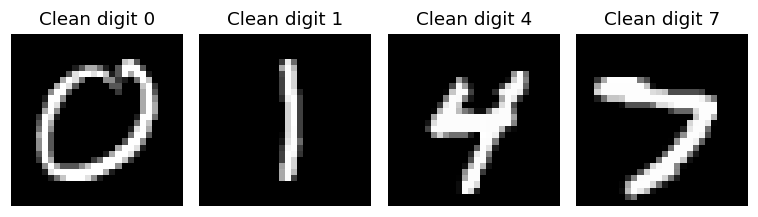

In [3]:
fig, axes = plt.subplots(1, len(x0), figsize=(7, 2))
for ax, image, label in zip(axes, x0, labels):
    ax.imshow(image[0], cmap="gray", vmin=-1, vmax=1)
    ax.set_title(f"Clean digit {label}")
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "day4_clean_inputs.png", bbox_inches="tight")
plt.show()

---
## Step 1: Minimal Example

### Timestep convention

The mathematical times are $t=0,\ldots,T$:

- $t=0$ is the clean input.
- Entry $t$ stores $\beta_t$ for the step from $t-1$ to $t$.
- A leading placeholder $\beta_0=0$ makes every table have length $T+1$.
  It is an indexing convention; actual noising steps still have $0<\beta_t<1$.

Consequently $\alpha_0=\bar\alpha_0=1$. We retain this entry explicitly
instead of treating array index zero as the first corrupted image.

In [10]:
# Provided linear schedule; all arrays include the clean-input entry.
betas = np.concatenate((
    np.array([0.0]),
    np.linspace(config["beta_start"], config["beta_end"], config["T"]),
))
assert betas.shape == (config["T"] + 1,)
assert betas[0] == 0 and np.all((betas[1:] > 0) & (betas[1:] < 1))

### TODO 1 of 3 — Accumulate the schedule (about 5 minutes)

Implement the two definitions you already used:

$$
\alpha_t=1-\beta_t,\qquad
\bar\alpha_t=\prod_{s=1}^{t}\alpha_s.
$$

Fill the two assignments in the function below. NumPy's **cumprod**
computes cumulative products. Include the leading clean-input entry.

In [11]:
def cumulative_coefficients(betas: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Return alpha and alpha_bar arrays, including the clean time t=0."""
    # TODO 1: replace the two None values using the definitions above.
    alphas = (1 - betas)
    alpha_bar = np.cumprod(alphas)
    if alphas is None or alpha_bar is None:
        raise NotImplementedError("Complete TODO 1: schedule coefficients.")
    return alphas, alpha_bar

In [12]:
# CHECKPOINT: a short schedule has a known two-step cumulative product.
probe_betas = np.array([0.0, 0.04, 0.25])
probe_alphas, probe_alpha_bar = cumulative_coefficients(probe_betas)
np.testing.assert_allclose(probe_alphas, [1.0, 0.96, 0.75])
np.testing.assert_allclose(probe_alpha_bar, [1.0, 0.96, 0.72])

alphas, alpha_bar = cumulative_coefficients(betas)
assert alphas.shape == alpha_bar.shape == betas.shape
assert alpha_bar[0] == 1.0
assert np.all(np.isfinite(alpha_bar)) and np.all(alpha_bar > 0)
assert np.all(np.diff(alpha_bar) <= 0)
np.testing.assert_allclose(alpha_bar[1], 1 - betas[1])
print("Schedule checks passed: t=0, t=1, and accumulated two-step values.")

Schedule checks passed: t=0, t=1, and accumulated two-step values.


### Predict, then inspect the curves

Before running: sketch the two amplitudes and the conditional noise variance.
Where should the amplitude curves cross vertically? Which curve represents
the covariance coefficient from your proof?

The dashed horizontal reference marks $\bar\alpha_t=1/2$ in the right plot;
the corresponding amplitudes in the left plot are $1/\sqrt{2}$.

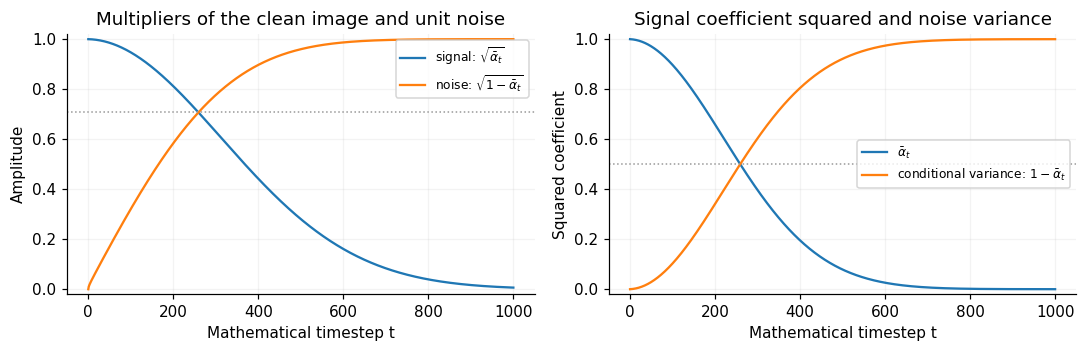

In [13]:
times = np.arange(config["T"] + 1)
signal_amplitude = np.sqrt(alpha_bar)
noise_amplitude = np.sqrt(1.0 - alpha_bar)
conditional_variance = 1.0 - alpha_bar
np.testing.assert_allclose(signal_amplitude**2 + noise_amplitude**2, 1.0)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
axes[0].plot(times, signal_amplitude, label=r"signal: $\sqrt{\bar\alpha_t}$")
axes[0].plot(times, noise_amplitude, label=r"noise: $\sqrt{1-\bar\alpha_t}$")
axes[0].axhline(1 / np.sqrt(2), color="0.6", ls=":", lw=1)
axes[0].set(xlabel="Mathematical timestep t", ylabel="Amplitude",
            title="Multipliers of the clean image and unit noise")
axes[1].plot(times, alpha_bar, label=r"$\bar\alpha_t$")
axes[1].plot(times, conditional_variance, label=r"conditional variance: $1-\bar\alpha_t$")
axes[1].axhline(0.5, color="0.6", ls=":", lw=1)
axes[1].set(xlabel="Mathematical timestep t", ylabel="Squared coefficient",
            title="Signal coefficient squared and noise variance")
for ax in axes:
    ax.set_ylim(-0.02, 1.02)
    ax.grid(alpha=0.15)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "day4_schedule.png", bbox_inches="tight")
plt.show()

### TODO 2 of 3 — One Gaussian step (about 5–10 minutes)

Implement the same transition as in your handwritten expansion:

$$
x_t=\sqrt{1-\beta_t}\,x_{t-1}+\sqrt{\beta_t}\,\epsilon_t.
$$

The helper receives the noise explicitly. This lets you test its arithmetic
with a fixed noise array; the sequential driver below will supply fresh
Gaussian draws at each step. Fill the single assignment.

In [14]:
def q_step(
    x_previous: np.ndarray, t: int, betas: np.ndarray, noise: np.ndarray
) -> np.ndarray:
    """Apply one Gaussian transition from mathematical time t-1 to t."""
    assert 1 <= t < len(betas), "q_step starts at t=1; t=0 is already clean."
    assert x_previous.shape == noise.shape
    beta_t = betas[t]
    # TODO 2: combine the previous state and supplied noise.
    x_t = (np.sqrt(1 - beta_t) * x_previous) + (np.sqrt(beta_t) * noise)
    if x_t is None:
        raise NotImplementedError("Complete TODO 2: the one-step equation.")
    return x_t

In [15]:
# CHECKPOINT: reproduce Day 1's scalar calculation and a second coordinate.
probe_x = np.array([[2.0, -1.0]])
probe_noise = np.array([[0.5, -2.0]])
expected_step = np.array([[2.0595917942265424, -1.3797958971132713]])
probe_step = q_step(probe_x, 1, probe_betas, probe_noise)
assert probe_step.shape == probe_x.shape
np.testing.assert_allclose(probe_step, expected_step, atol=1e-12)
print("One-step check passed: signal scaling and noise standard deviation.")

One-step check passed: signal scaling and noise standard deviation.


---
## Step 2: Interpret the Result

### Provided helper: broadcast a coefficient over images

A batch can share one timestep or have one timestep per image.
The helper turns selected table entries into shapes that broadcast over
the image coordinates. This is provided so the exercise stays focused on
the noising equation.

In [16]:
def coefficient_at(
    table: np.ndarray, t: int | np.ndarray, batch: np.ndarray
) -> np.ndarray:
    """Select a shared or per-image coefficient with broadcastable shape."""
    t_array = np.asarray(t)
    assert np.issubdtype(t_array.dtype, np.integer), "Use integer timesteps."
    assert np.all((t_array >= 0) & (t_array < len(table)))
    if t_array.ndim == 0:
        return np.asarray(table[int(t_array)])
    assert t_array.shape == (batch.shape[0],), "Supply one time per image."
    return table[t_array].reshape((batch.shape[0],) + (1,) * (batch.ndim - 1))


assert coefficient_at(np.ones(3), 0, x0).shape == ()
assert coefficient_at(np.ones(3), np.zeros(len(x0), dtype=int), x0).shape == (4, 1, 1, 1)

### TODO 3 of 3 — Direct sampling (about 5–10 minutes)

Implement the closed form you derived:

$$
x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon.
$$

Fill the assignment using **alpha_bar_t**, the clean input, and the supplied
noise. Keep the raw result: Gaussian corruption is allowed to leave
$[-1,1]$. Display clipping is handled separately.

In [17]:
def q_sample(
    x0: np.ndarray, t: int | np.ndarray, alpha_bar: np.ndarray, noise: np.ndarray
) -> np.ndarray:
    """Sample the conditional marginal at time t using supplied unit noise."""
    assert x0.shape == noise.shape
    alpha_bar_t = coefficient_at(alpha_bar, t, x0)
    # TODO 3: combine the clean input and supplied noise.
    x_t = np.sqrt(alpha_bar_t) * x0 + np.sqrt(1 - alpha_bar_t) * noise
    if x_t is None:
        raise NotImplementedError("Complete TODO 3: the direct-sampling equation.")
    return x_t

In [18]:
# CHECKPOINT: t=0, t=1, the two-step result, shapes, and raw values.
check_noise = np.random.default_rng(SEED + 1).standard_normal(x0.shape)
np.testing.assert_array_equal(q_sample(x0, 0, alpha_bar, check_noise), x0)
np.testing.assert_allclose(
    q_sample(x0, 1, alpha_bar, check_noise),
    q_step(x0, 1, betas, check_noise),
)
expected_two_step = (
    np.sqrt(0.72) * probe_x + np.sqrt(0.28) * probe_noise
)
np.testing.assert_allclose(
    q_sample(probe_x, 2, probe_alpha_bar, probe_noise), expected_two_step,
)
batch_times = np.array([0, 1, 250, config["T"]])
mixed_times = q_sample(x0, batch_times, alpha_bar, check_noise)
assert mixed_times.shape == x0.shape and np.all(np.isfinite(mixed_times))
for row, t in enumerate(batch_times):
    np.testing.assert_allclose(
        mixed_times[row:row + 1],
        q_sample(x0[row:row + 1], int(t), alpha_bar, check_noise[row:row + 1]),
    )
# A deliberately large supplied noise value catches clipping inside q_sample.
assert q_sample(x0, config["T"], alpha_bar, np.full_like(x0, 3.0)).max() > 1.0
print("Direct-sampling checks passed: boundaries, two-step formula, broadcasting, raw range.")

Direct-sampling checks passed: boundaries, two-step formula, broadcasting, raw range.


### Provided plotting: show the same images across time

Each row keeps the same clean input; columns show selected mathematical
times. The display uses a fixed gray scale and clips a copy for viewing.
The saved arrays and all calculations retain the raw unbounded samples.

In [19]:
def show_snapshots(
    snapshots: dict[int, np.ndarray], title: str, filename: str
) -> None:
    """Show fixed-scale image snapshots and save a small figure."""
    display_times = list(config["display_times"])
    fig, axes = plt.subplots(
        len(x0), len(display_times), figsize=(11, 6), squeeze=False,
    )
    for row, label in enumerate(labels):
        for col, t in enumerate(display_times):
            ax = axes[row, col]
            ax.imshow(np.clip(snapshots[t][row, 0], -1, 1),
                      cmap="gray", vmin=-1, vmax=1)
            ax.set_xticks([])
            ax.set_yticks([])
            if row == 0:
                ax.set_title(f"t={t}")
            if col == 0:
                ax.set_ylabel(f"Digit {label}")
    fig.suptitle(title)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    fig.savefig(FIGURE_DIR / filename, bbox_inches="tight")
    plt.show()

### Sequential trajectory

Before running, predict which displayed columns will still retain recognizable
structure. The driver uses your one-step function, with a fresh noise array
for every step. Resetting the local generator makes this cell reproducible.

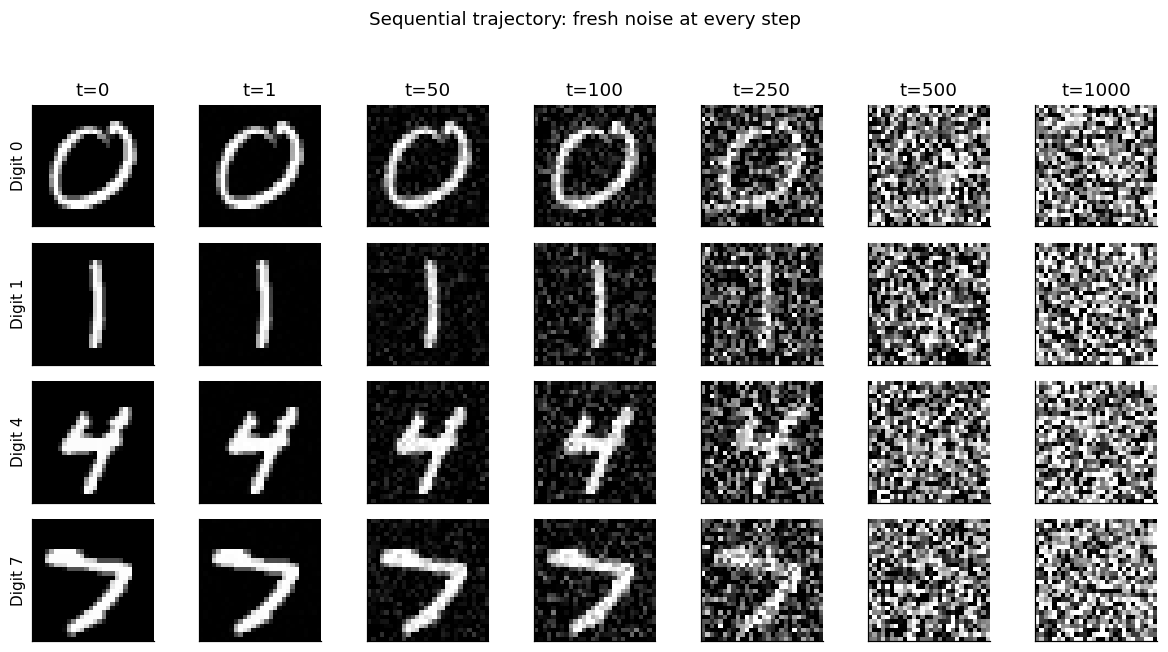

In [22]:
sequential_rng = np.random.default_rng(SEED + 10)
x_previous = x0.copy()
sequential_snapshots = {0: x0.copy()}
for t in range(1, config["T"] + 1):
    fresh_noise = sequential_rng.standard_normal(x0.shape)
    x_previous = q_step(x_previous, t, betas, fresh_noise)
    if t in config["display_times"]:
        sequential_snapshots[t] = x_previous.copy()

assert set(sequential_snapshots) == set(config["display_times"])
assert all(x.shape == x0.shape and np.all(np.isfinite(x))
           for x in sequential_snapshots.values())
np.testing.assert_array_equal(sequential_snapshots[0], x0)
show_snapshots(
    sequential_snapshots, "Sequential trajectory: fresh noise at every step",
    "day4_sequential.png",
)

### Direct conditional samples

The next grid uses your direct formula with fresh noise for each displayed
time. These columns are separate samples from $q(x_t\mid x_0)$; they do not
constitute a sequential Markov trajectory.

You should expect agreement in the conditional law at each time, without
pixel-for-pixel agreement with the independently generated sequential grid.
The pictures illustrate corruption; Day 5 will check moments with repeated
draws for fixed clean inputs.

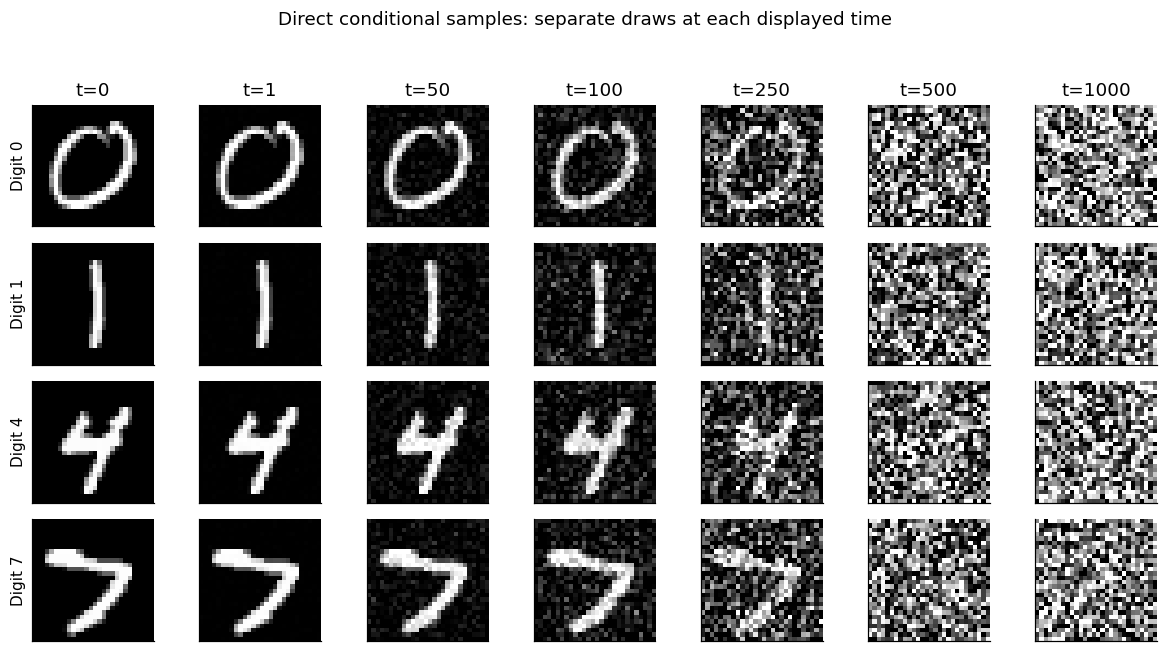

Raw terminal range — sequential: [-3.32, 3.70]
Raw terminal range — direct: [-3.45, 3.76]


In [23]:
direct_rng = np.random.default_rng(SEED + 20)
direct_snapshots = {0: x0.copy()}
for t in config["display_times"][1:]:
    fresh_noise = direct_rng.standard_normal(x0.shape)
    direct_snapshots[t] = q_sample(x0, t, alpha_bar, fresh_noise)

assert set(direct_snapshots) == set(config["display_times"])
assert all(x.shape == x0.shape and np.all(np.isfinite(x))
           for x in direct_snapshots.values())
np.testing.assert_array_equal(direct_snapshots[0], x0)
show_snapshots(
    direct_snapshots, "Direct conditional samples: separate draws at each displayed time",
    "day4_direct.png",
)
print(f"Raw terminal range — sequential: [{x_previous.min():.2f}, {x_previous.max():.2f}]")
print(f"Raw terminal range — direct: [{direct_snapshots[config['T']].min():.2f}, "
      f"{direct_snapshots[config['T']].max():.2f}]")

In [24]:
# Coefficients predicted by the schedule; these are not empirical moment estimates.
print("    t   signal amplitude   noise amplitude   conditional variance")
for t in config["display_times"]:
    print(f"{t:5d}   {signal_amplitude[t]:16.6f}   "
          f"{noise_amplitude[t]:15.6f}   {conditional_variance[t]:20.6f}")
assert conditional_variance[0] == 0
print("Run settings:", config)

    t   signal amplitude   noise amplitude   conditional variance
    0           1.000000          0.000000               0.000000
    1           0.999950          0.010000               0.000100
   50           0.985401          0.170248               0.028984
  100           0.947110          0.320908               0.102982
  250           0.723937          0.689866               0.475915
  500           0.280334          0.959902               0.921413
 1000           0.006353          0.999980               0.999960
Run settings: {'seed': 15, 'T': 1000, 'beta_start': 0.0001, 'beta_end': 0.02, 'digits': (0, 1, 4, 7), 'display_times': (0, 1, 50, 100, 250, 500, 1000), 'normalization': 'uint8 / 127.5 - 1'}


---
## Exercise

Write one or two sentences per item in your working copy, then bring these
answers and any failed checkpoint to our discussion.

1. **Boundary and scale:** What does the $t=0$ result show? Why can the
   raw noisy values extend beyond the normalized image range?
2. **Curves and images:** Pick one intermediate time. Use the coefficients
   to explain what you observe in a digit, distinguishing noise amplitude
   from conditional variance.
3. **Two constructions:** What agrees between sequential and direct
   sampling? What evidence would be needed to check that agreement beyond
   comparing four pictures?

### Your observations — consolidated after discussion

**Discussion and final learner read-through completed on 2026-11-03.**

1. **Boundary and scale:** At $t=0$, I get the clean image $x_0$ because the signal amplitude is one and the noise amplitude is zero. Each standard-normal noise coordinate has about a 68% chance of falling within $[-1,1]$, but values outside that range are possible. Adding a scaled noise draw to a scaled clean pixel can therefore take the raw result outside the normalized image range; the plotting code clips only for display.

2. **Curves and images:** At $t=100$, I can still recognize the four digits despite visible noise. The direct formula is approximately $x_{100}=0.9471\,x_0+0.3209\,\epsilon$: every clean pixel value is multiplied by $0.9471$, and each corresponding noise draw is multiplied by $0.3209$. A noise draw of $0.1$ contributes about $0.03209$, and signed noise can raise or lower the pixel value. The conditional variance per coordinate is $0.3209^2\approx0.10298$; this is not a percentage of the image. Direct sampling starts from $x_0$; the single-step update to time 100 starts from $x_{99}$ and uses $\beta_{100}$.

3. **Two constructions:** The sequential and direct grids show similar qualitative corruption and both recover the clean inputs at $t=0$. For the same fixed clean input and timestep, both sample from the conditional distribution derived on Day 3, so their conditional means and covariances agree; individual draws need not match pixel by pixel. To check the implementations numerically, I would fix one clean pixel and a timestep, collect many independent samples from each method, and estimate their means and variances by Monte Carlo. My suggested 100 draws would be a starting approximation with sampling error. This numerical experiment remains for Day 5.

For that proposed check, the reference mean and variance for a fixed clean coordinate $x_{0,j}$ are

$$
\mu_{t,j}=\sqrt{\bar\alpha_t}\,x_{0,j},
\qquad
v_{t,j}=1-\bar\alpha_t.
$$

Estimate variance across the individual draws around their sample mean, while keeping the clean input and timestep fixed.

### Review notes — attempts and corrections

These observations consolidate my original answers and the subsequent discussion with Codex:

- I initially described the conditional variance near $0.103$ as roughly 10% noise and 90% image. We corrected this to distinguish amplitudes, conditional variance, and proportions of an image.
- I briefly used $x_{99}$ while describing direct sampling. I then correctly wrote the single-step update below and distinguished it from the direct formula starting at $x_0$.
- I initially suggested comparing individual pixel differences. After a prompt about fixing a clean pixel and timestep, I proposed repeated sampling and Monte Carlo moment estimates instead.

The corrected single-step update is

$$
x_{100}=\sqrt{1-\beta_{100}}\,x_{99}
+\sqrt{\beta_{100}}\,\epsilon_{100},
\qquad \epsilon_{100}\sim\mathcal N(0,I).
$$

**Added clarification from Codex:** Given a fixed $x_0$, the signal term is deterministic, so all conditional variance comes from noise. Across different clean images, the variance balance also depends on the clean-data covariance. Normalizing the pixel range to $[-1,1]$ does not impose unit data variance.

**Code verification:** All three completed implementations were reviewed and all 16 code cells passed a fresh execution on 2026-11-03. The second schedule and repeated-draw moment checks are the next experiment.

See the [full Day 4 discussion and saved figures](../notes/w15_forward_process_discrete.md#day-4--implementing-and-interpreting-forward-noising) for the evidence and review record.

---
## Wrap-up

**Status:** Day 4 completed on 2026-11-03. The learner reviewed and approved the notebook, consolidated observations, and correction record.

**Day 4 stopping point:** all three exercise checkpoints pass; you have
the coefficient plot and both image grids; normalization, seed, schedule,
timesteps, and raw-value ranges are recorded; and you can explain three
observations. Keep questions visible and stop within the session budget.
Implementation passing its checks does not by itself record learner review
or complete the whole week.

**Common pitfalls:** forgetting the square root on the noise coefficient;
using a per-step $\alpha_t$ where $\bar\alpha_t$ is needed; shifting array
indices by one; clipping the stored samples; treating direct snapshots as
a sequential trajectory.

**Optional later extension:** find the first timestep where the signal
amplitude drops below 0.1 and relate it to $\bar\alpha_t$.

**Day 5:** compare a second schedule and empirically verify the conditional
mean and covariance with repeated independent draws for fixed clean
coordinates. These tasks can extend this notebook after today's review.
The schedule convention and noising equations also carry into Week 16.